# Упражнения по регуляризации и методу градиентного спуска

## Вопрос 1: Генерация нелинейных данных с гетероскедастичным шумом

В реальных задачах шум в данных часто зависит от значения входных признаков (гетероскедастичность).

* Сгенерируйте 250 равномерно распределенных точек $x$ на отрезке $[0, 5]$.
* Вычислите истинное значение целевой переменной по формуле: $y_{\\text{true}} = 2.5 \\cdot \\sin(1.5 x) + 0.3 x^2 - 1.5$.

* Добавьте гауссов шум, дисперсия которого растет линейно с ростом $x$: $\\sigma(x) = 0.15 \\cdot (1 + 0.8x)$.

* Разделите данные на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.
* Постройте график тренировочных, тестовых точек и истинной функции.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def true_function(x):
    return 2.5 * np.sin(1.5 * x) + 0.3 * x ** 2 - 1.5

rng = np.random.default_rng(42)

# равномерно распределенные, то есть из равномерного распределения, а не с ровным шагом
x = rng.uniform(0, 5, 250)
# в формуле sigma(x) это стандартное отклонение шума, его и передаем в scale
sigma = 0.15 * (1 + 0.8 * x)
y = true_function(x) + rng.normal(0, sigma)

X_train, X_test, y_train, y_test = train_test_split(x.reshape(-1, 1), y, test_size=0.3, random_state=42)


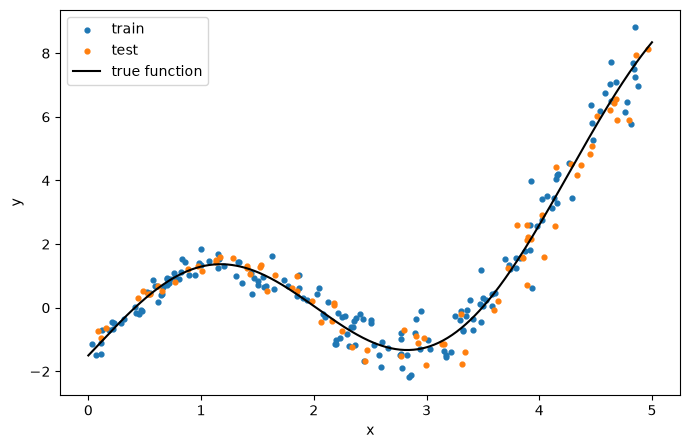

In [2]:
x_line = np.linspace(0, 5, 500)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, s=12, label='train')
plt.scatter(X_test, y_test, s=12, label='test')
plt.plot(x_line, true_function(x_line), color='black', label='true function')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## Вопрос 2: Исследование полиномов высокой степени и феномена Рунге

При слишком высокой степени полинома модель стремится идеально пройти через все точки обучающей выборки, образуя сильные осцилляции на краях интервала.

* Сформируйте полиномиальные признаки 25-й степени (`degree=25`).

* Обучите обычную линейную регрессию (`LinearRegression`) без регуляризации.

* Оцените $RMSE$ на обучающей и тестовой выборках.

Постройте график предсказаний модели на всем отрезке $[0, 5]$. Проанализируйте осцилляции модели на границах интервала.

In [3]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# функция rmse как в уроке
def rmse(ytrue, ypredicted):
    return np.sqrt(mean_squared_error(ytrue, ypredicted))

# x**25 доходит до 5**25, это примерно 3e17, и без масштабирования LinearRegression считается с огромной
# численной ошибкой. StandardScaler после PolynomialFeatures саму модель не меняет, только делает расчет точным
poly_lr = make_pipeline(PolynomialFeatures(degree=25), StandardScaler(), LinearRegression())
poly_lr.fit(X_train, y_train)

print('RMSE train:', round(rmse(y_train, poly_lr.predict(X_train)), 3))
print('RMSE test:', round(rmse(y_test, poly_lr.predict(X_test)), 3))
print('крайние точки train:', round(X_train.min(), 3), round(X_train.max(), 3))


RMSE train: 0.46
RMSE test: 0.632
крайние точки train: 0.037 4.878


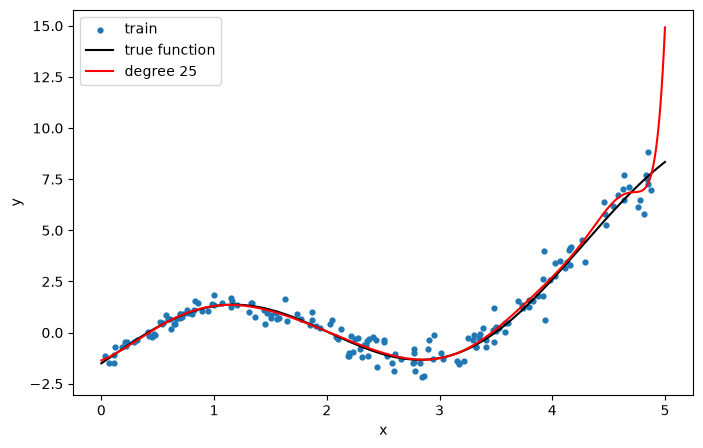

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, s=12, label='train')
plt.plot(x_line, true_function(x_line), color='black', label='true function')
plt.plot(x_line, poly_lr.predict(x_line.reshape(-1, 1)), color='red', label='degree 25')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

На большей части отрезка полином идет близко к истинной функции, а у правого края резко уходит вверх. Последняя точка train около 4.88, дальше полином ничем не ограничен, а при степени 25 он очень быстро растет. У левого края точки train есть почти до самого 0, поэтому там отклонение небольшое.

RMSE на test (0.63) заметно больше, чем на train (0.46), значит модель переобучилась: она подстраивается под шум, а там, где точек нет, ведет себя непредсказуемо. Это и есть феномен Рунге: у полиномов высокой степени ошибка сильнее всего растет на краях интервала.

## Вопрос 3: Диагностика Bias-Variance с помощью кривых обучения (Learning Curves)

Кривые обучения позволяют определить, принесет ли пользу добавление новых данных или необходима регуляризация.\

* Напишите функцию для расчета и построения кривых обучения с помощью `learning_curve` из `sklearn.model_selection`.

* Постройте кривые обучения для неуправляемой линейной регрессии (степень 15) и Ridge-регрессии (степень 15, $\\alpha = 1.0$).

* Объясните разрыв (*generalization gap*) между ошибкой на обучении и валидации для обеих моделей."

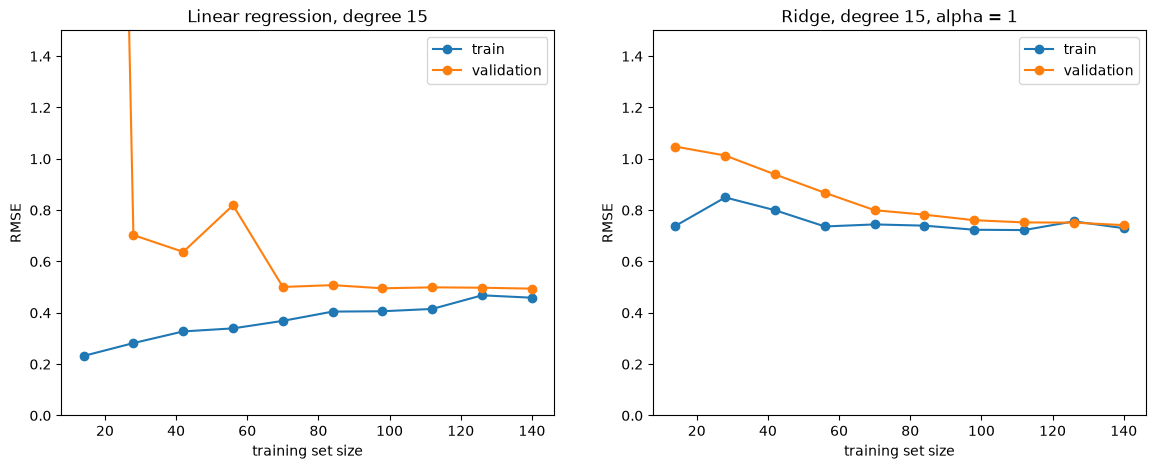

In [5]:
from sklearn.model_selection import learning_curve
from sklearn.linear_model import Ridge

def plot_learning_curve(model, title, ax):
    # для каждого размера обучающей части считаем ошибку на train и на валидации (cv=5)
    sizes, train_scores, valid_scores = learning_curve(model, X_train, y_train, cv=5,
                                                       train_sizes=np.linspace(0.1, 1.0, 10),
                                                       scoring='neg_root_mean_squared_error')
    # scoring возвращает RMSE со знаком минус, поэтому меняем знак
    ax.plot(sizes, -train_scores.mean(axis=1), marker='o', label='train')
    ax.plot(sizes, -valid_scores.mean(axis=1), marker='o', label='validation')
    # ylim, потому что на самой маленькой выборке у линейной регрессии ошибка около 10 и остальное не видно
    ax.set(title=title, xlabel='training set size', ylabel='RMSE', ylim=(0, 1.5))
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_learning_curve(make_pipeline(PolynomialFeatures(15), StandardScaler(), LinearRegression()),
                    'Linear regression, degree 15', axes[0])
plot_learning_curve(make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=1.0)),
                    'Ridge, degree 15, alpha = 1', axes[1])
plt.show()


У линейной регрессии без регуляризации на маленькой выборке ошибка на train маленькая (0.23), а на валидации огромная (около 10): 16 коэффициентов подстраиваются под 14 точек, это переобучение, то есть высокая дисперсия. С ростом выборки разрыв почти исчезает (0.46 на train и 0.49 на валидации), обе ошибки подходят к уровню шума, значит этой модели новые данные помогают.

У Ridge с alpha = 1 разрыв маленький при любом размере выборки, но обе кривые останавливаются примерно на 0.74, это выше, чем у линейной регрессии. Значит здесь недообучение (высокое смещение): штраф слишком сильный, и новые данные уже не помогут, лучше уменьшить alpha.

## Вопрос 4: Подготовка продвинутых признаков и обработка Ames Housing

Перейдем к реальному набору данных о продажах недвижимости `Ames_Housing_Sales.csv`.

* Загрузите датасет, выполните One-Hot Encoding категориальных признаков.

* Проверьте признаки на асимметрию (`skew > 0.75`) и примените преобразование `np.log1p`.

* Создайте парные взаимодействия признаков только для ключевых числовых переменных (`LotArea`, `GrLivArea`, `TotalBsmtSF`), используя `PolynomialFeatures(interaction_only=True)`.\

Разделите данные на обучающую и тестовую выборки (70/30).

In [6]:
import os

data_path = ['..', '..', '..', 'datasets']
filepath = os.sep.join(data_path + ['Ames_Housing_Sales.csv'])
data = pd.read_csv(filepath)

# one-hot для всех текстовых колонок. select_dtypes, потому что в pandas 3 текст имеет тип str, а не object
cat_cols = data.select_dtypes(exclude='number').columns
data = pd.get_dummies(data, columns=cat_cols)
data.shape


(1379, 284)

In [7]:
# асимметрию смотрим только у числовых колонок, dummy колонки после get_dummies имеют тип bool и сюда не попадают
num_cols = data.select_dtypes('number').columns
skew_vals = data[num_cols].skew()
skew_cols = skew_vals[skew_vals > 0.75].index
print(len(skew_cols), 'колонок с skew > 0.75')
print(skew_vals[skew_cols].sort_values(ascending=False).round(2).head(10))

# SalePrice тоже скошена, поэтому логарифмируем и ее. Тогда RMSE ниже считается в логарифмах,
# то есть примерно как относительная ошибка в цене
data[skew_cols] = np.log1p(data[skew_cols])

24 колонок с skew > 0.75
MiscVal          24.84
PoolArea         14.41
LotArea          12.01
LowQualFinSF     10.71
3SsnPorch        10.01
KitchenAbvGr      5.09
BsmtFinSF2        4.19
ScreenPorch       3.99
BsmtHalfBath      3.92
EnclosedPorch     3.21
dtype: float64


In [8]:
key_cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF']
# interaction_only=True дает только произведения пар без квадратов, include_bias=False без колонки из единиц
pf_inter = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
inter = pf_inter.fit_transform(data[key_cols])
inter_names = pf_inter.get_feature_names_out(key_cols)

# первые три колонки это сами признаки, они уже есть, поэтому добавляем только три произведения
# (по порядку из условия: сначала log1p, потом произведения)
for name, values in zip(inter_names[3:], inter[:, 3:].T):
    data[name] = values

X_ames = data.drop(columns='SalePrice')
y_ames = data['SalePrice']
X_train_ames, X_test_ames, y_train_ames, y_test_ames = train_test_split(X_ames, y_ames, test_size=0.3, random_state=42)
print(X_train_ames.shape, X_test_ames.shape)

(965, 286) (414, 286)


## Вопрос 5: Двумерный сетчатый поиск гиперпараметров ElasticNet с GridSearchCV

Регрессия `ElasticNet` комбинирует $L_1$ и $L_2$ штрафы через два ключевых гиперпараметра: $\\alpha$ (сила регуляризации) и `l1_ratio` (доля $L_1$-штрафа).

* Настройте сетку параметров: `alpha`: `[1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0]`, `l1_ratio`: `[0.1, 0.3, 0.5, 0.7, 0.9]`.

* Запустите `GridSearchCV` с 5-кратной кросс-валидацией (`cv=5`) и метрикой `neg_root_mean_squared_error`.

* Визуализируйте результаты сетчатого поиска в виде тепловой карты (`sns.heatmap`).

* Выведите оптимальные параметры и оцените итоговое $RMSE$ на тестовой выборке."

In [9]:
import seaborn as sns
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# StandardScaler внутри pipeline: штраф зависит от масштаба признаков, а scaler учится только на train части каждого fold
# max_iter больше, чем по умолчанию, иначе при маленьком alpha ElasticNet не успевает сойтись
pipe = Pipeline([('scaler', StandardScaler()), ('enet', ElasticNet(max_iter=50000))])
params = {
    'enet__alpha': [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0],
    'enet__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}
grid = GridSearchCV(pipe, params, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid.fit(X_train_ames, y_train_ames)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=50000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'enet__alpha': [0.0001, 0.001, ...], 'enet__l1_ratio': [0.1, 0.3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0C

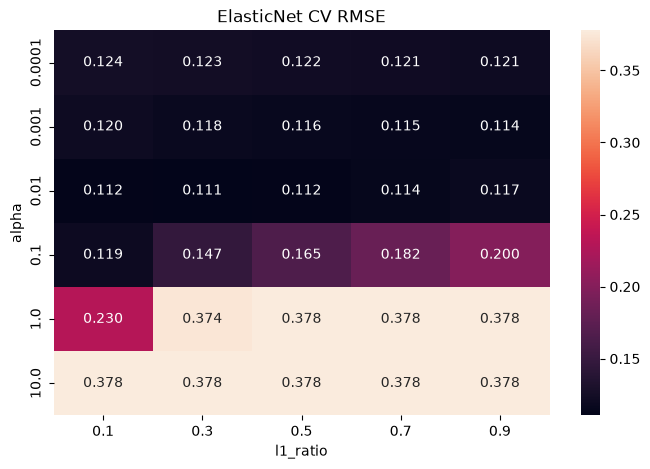

{'enet__alpha': 0.01, 'enet__l1_ratio': 0.3}
RMSE на кросс-валидации: 0.1106
RMSE на test: 0.1503


In [10]:
res = pd.DataFrame(grid.cv_results_)
table = res.pivot(index='param_enet__alpha', columns='param_enet__l1_ratio', values='mean_test_score')

# scoring со знаком минус, поэтому -table это обычный RMSE
plt.figure(figsize=(8, 5))
sns.heatmap(-table, annot=True, fmt='.3f')
plt.title('ElasticNet CV RMSE')
plt.xlabel('l1_ratio')
plt.ylabel('alpha')
plt.show()

print(grid.best_params_)
print('RMSE на кросс-валидации:', round(-grid.best_score_, 4))
print('RMSE на test:', round(rmse(y_test_ames, grid.predict(X_test_ames)), 4))

# RMSE 0.378 там, где все коэффициенты обнулились (alpha 10 и почти вся строка alpha 1):
# тогда модель предсказывает просто среднюю цену

## Вопрос 6: Анализ разряженности (Sparsity) моделей Lasso и отбор признаков

$L_1$-регуляризация способна занулять коэффициенты неинформативных признаков.

* Обучите модель `LassoCV` с диапазоном `alphas = np.logspace(-4, 1, 50)`.

* Постройте график зависимости количества ненулевых коэффициентов от значения $\\alpha$.
* Выделите ТОП-10 наиболее важных признаков с наибольшими абсолютными значениями коэффициентов при оптимальном $\\alpha$.
* Какая доля признаков была полностью исключена из модели?

In [11]:
from sklearn.linear_model import LassoCV, Lasso

# Lasso тоже чувствительна к масштабу признаков, scaler учим только на train
# (это же масштабирование нужно в упражнении 7)
scaler_ames = StandardScaler()
X_train_scaled = scaler_ames.fit_transform(X_train_ames)
X_test_scaled = scaler_ames.transform(X_test_ames)

alphas = np.logspace(-4, 1, 50)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000).fit(X_train_scaled, y_train_ames)
print('лучшее alpha:', round(lasso_cv.alpha_, 5))
print('RMSE на test:', round(rmse(y_test_ames, lasso_cv.predict(X_test_scaled)), 4))


лучшее alpha: 0.00339
RMSE на test: 0.1779


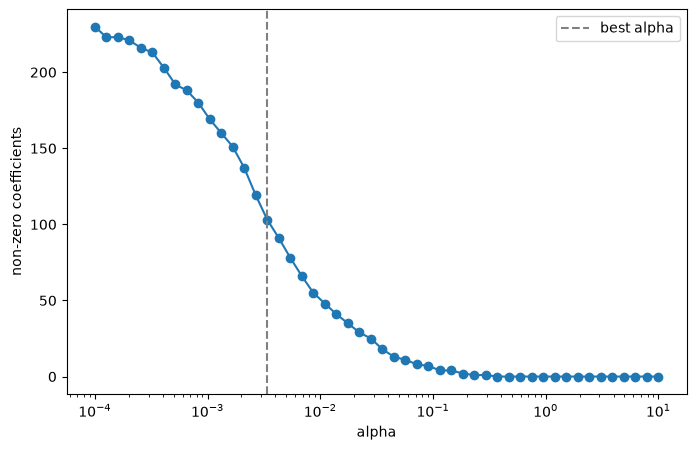

In [12]:
# LassoCV не хранит коэффициенты для каждого alpha, поэтому обучаем Lasso на каждом alpha отдельно
nonzero = []
for a in alphas:
    lasso = Lasso(alpha=a, max_iter=10000).fit(X_train_scaled, y_train_ames)
    nonzero.append(np.sum(lasso.coef_ != 0))

plt.figure(figsize=(8, 5))
plt.semilogx(alphas, nonzero, marker='o')
plt.axvline(lasso_cv.alpha_, color='gray', linestyle='--', label='best alpha')
plt.xlabel('alpha')
plt.ylabel('non-zero coefficients')
plt.legend()
plt.show()

In [13]:
coefs = pd.Series(lasso_cv.coef_, index=X_train_ames.columns)
top10 = coefs.abs().sort_values(ascending=False).head(10).index
print(coefs[top10].round(3))

n_zero = np.sum(lasso_cv.coef_ == 0)
print('исключено признаков:', n_zero, 'из', len(coefs), 'доля', round(n_zero / len(coefs), 2))

GrLivArea            0.086
OverallQual          0.073
LotArea GrLivArea    0.065
YearBuilt            0.050
PoolQC_Gd           -0.047
OverallCond          0.038
1stFlrSF             0.025
BsmtFinSF1           0.025
MSZoning_C (all)    -0.023
GarageCars           0.023
dtype: float64
исключено признаков: 183 из 286 доля 0.64


При лучшем alpha (около 0.0034) Lasso обнулила 183 коэффициента из 286, то есть из модели полностью исключено примерно 64% признаков. В основном это dummy колонки после one-hot (166 из 183). Среди самых важных остались площадь дома (GrLivArea), общее качество (OverallQual), год постройки и наше взаимодействие LotArea GrLivArea.

На графике видно, что с ростом alpha ненулевых коэффициентов становится все меньше, а примерно с alpha = 0.37 обнуляются все.

## Вопрос 7: Настройка схем скорости обучения (Learning Rate Schedules) в SGDRegressor

Алгоритм стохастического градиентного спуска критически чувствителен к масштабу данных и выбору правила изменения шага $\\eta$.

* Отсштабируйте признаки `X_train_ames` и `X_test_ames` с помощью `StandardScaler`.

Обучите четыре версии `SGDRegressor` с регуляризацией `penalty='elasticnet'`, используя различные стратегии `learning_rate`:

1. `'constant'` (`eta0=0.01`)

2. `'optimal'`

3. `'invscaling'` (`eta0=0.01`, `power_t=0.25`)

4. `'adaptive'` (`eta0=0.01`)

* Сравните полученные значения $RMSE$ и общее число итераций до сходимости (`n_iter_`).

In [14]:
from sklearn.linear_model import SGDRegressor

# X_train_scaled и X_test_scaled уже отмасштабированы StandardScaler в упражнении 6
schedules = {
    'constant': {'learning_rate': 'constant', 'eta0': 0.01},
    'optimal': {'learning_rate': 'optimal'},
    'invscaling': {'learning_rate': 'invscaling', 'eta0': 0.01, 'power_t': 0.25},
    'adaptive': {'learning_rate': 'adaptive', 'eta0': 0.01},
}

score_list = list()
for name, params in schedules.items():
    # random_state, чтобы порядок объектов в SGD был одинаковым при перезапуске
    sgd = SGDRegressor(penalty='elasticnet', random_state=42, **params)
    sgd.fit(X_train_scaled, y_train_ames)
    score_list.append((name, rmse(y_test_ames, sgd.predict(X_test_scaled)), sgd.n_iter_))

pd.DataFrame(score_list, columns=['learning_rate', 'RMSE', 'n_iter'])


,learning_rate,RMSE,n_iter
0,constant,2.329094e+12,6
1,optimal,2.823702e+13,72
2,invscaling,2.790152e+02,6
3,adaptive,2.438622e+11,36


In [15]:
# RMSE огромный, значит SGD разошелся. Для квадратичной ошибки шаг устойчив, только если eta * ||x||**2 < 2,
# а после StandardScaler у строки ||x||**2 примерно равно числу признаков
row_norms = np.sum(X_train_scaled ** 2, axis=1)
print('||x||**2: в среднем', round(row_norms.mean()), 'максимум', round(row_norms.max()))

# поэтому повторим то же самое с шагом в 10 раз меньше
score_list = list()
for name, params in schedules.items():
    params = dict(params)
    if 'eta0' in params:
        params['eta0'] = 0.001
    sgd = SGDRegressor(penalty='elasticnet', random_state=42, **params)
    sgd.fit(X_train_scaled, y_train_ames)
    score_list.append((name, rmse(y_test_ames, sgd.predict(X_test_scaled)), sgd.n_iter_))

pd.DataFrame(score_list, columns=['learning_rate', 'RMSE', 'n_iter'])

# С eta0 = 0.01 разошлись все четыре схемы: 0.01 * 275 больше 2. Маленькое n_iter у constant и invscaling
# не значит быструю сходимость, SGD просто останавливается, когда ошибка 5 эпох подряд не уменьшается.
# С шагом 0.001 сходятся схемы, которые уменьшают шаг по ходу обучения: invscaling (RMSE 0.179 за 59 итераций)
# и adaptive (0.227 за 48). constant не сходится и так, потому что у отдельных строк ||x||**2 доходит до 2899.
# optimal от eta0 не зависит, шаг там считается через alpha, и для этой регрессии он слишком большой.

||x||**2: в среднем 275 максимум 2899


,learning_rate,RMSE,n_iter
0,constant,8.780643e+00,8
1,optimal,2.823702e+13,72
2,invscaling,1.789560e-01,59
3,adaptive,2.272818e-01,48


## Вопрос 8: Сравнительный анализ устойчивости моделей к выбросам (Outliers)

Среднеквадратичная ошибка ($MSE$) в оптимизации градиентным спуском квадратично штрафует отклонения, делая модели чувствительными к аномалиям.

* Добавьте в 5% случайных точек обучающей выборки `y_train_ames` аномальные выбросы (увеличьте их значение в 3 раза).

* Обучите следующие модели на искаженных данных:

1. OLS (`LinearRegression`)
2. Ridge (`RidgeCV`)     
3. SGDRegressor с функциями потерь `loss='squared_error'` ($L_2$) и `loss='huber'` (Huber loss, комбинирующий $L_1$ и $L_2$).

* Оцените $RMSE$ и $MAE$ каждой модели на чистой тестовой выборке `y_test_ames`.

Сделайте выводы об устойчивости функции потерь Хьюбера по сравнению с классической регрессией.

     

In [16]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error

# 5% случайных точек train делаем выбросами: цена в 3 раза больше. y у нас в логарифмах, поэтому это + log(3)
rng = np.random.default_rng(42)
y_train_bad = y_train_ames.copy()
idx = rng.choice(len(y_train_bad), int(0.05 * len(y_train_bad)), replace=False)
y_train_bad.iloc[idx] = y_train_bad.iloc[idx] + np.log(3)
print('выбросов:', len(idx))


выбросов: 48


In [17]:
models = {
    'OLS': LinearRegression(),
    'RidgeCV': RidgeCV(),
    # шаг 0.001, потому что с 0.01 SGD с квадратичной ошибкой расходится (упражнение 7)
    'SGD squared_error': SGDRegressor(loss='squared_error', eta0=0.001, random_state=42),
    # у Хьюбера градиент ограничен, поэтому шаг по умолчанию (0.01) ему не опасен, а с 0.001 он не успевает дойти до y около 12
    'SGD huber': SGDRegressor(loss='huber', random_state=42),
}

score_list = list()
for name, model in models.items():
    # для сравнения сначала та же модель на чистых данных
    model.fit(X_train_scaled, y_train_ames)
    rmse_clean = rmse(y_test_ames, model.predict(X_test_scaled))
    model.fit(X_train_scaled, y_train_bad)
    pred = model.predict(X_test_scaled)
    score_list.append((name, rmse_clean, rmse(y_test_ames, pred), mean_absolute_error(y_test_ames, pred)))

pd.DataFrame(score_list, columns=['model', 'RMSE clean train', 'RMSE with outliers', 'MAE with outliers'])

,model,RMSE clean train,RMSE with outliers,MAE with outliers
0,OLS,0.644729,1.261629,0.237315
1,RidgeCV,0.160157,0.219728,0.144872
2,SGD squared_error,0.179020,0.206445,0.132583
3,SGD huber,0.155516,0.159353,0.093861


Модели с квадратичной ошибкой заметно испортились от выбросов: у OLS RMSE вырос с 0.645 до 1.262, у RidgeCV с 0.160 до 0.220, у SGD с squared_error с 0.179 до 0.206. У SGD с функцией потерь Хьюбера ошибка почти не изменилась (0.156 и 0.159), и с выбросами она лучшая из всех, по MAE тоже (0.094).

Так получается, потому что квадратичная ошибка штрафует отклонение в квадрате, и несколько сильно завышенных цен тянут модель к себе. У Хьюбера для маленьких отклонений штраф квадратичный, а для больших (больше epsilon) растет линейно, поэтому выбросы почти не влияют на коэффициенты. Следовательно, если в данных могут быть выбросы, Huber loss устойчивее классической регрессии. Отдельно видно, что OLS и без выбросов хуже остальных (0.645): без регуляризации на 286 признаках модель переобучается.